# Cell types, growth and UMAP flow

Start by preparing a Scanpy-compatible AnnData. COATI recommends the following names; Scanpy itself permits other observation-column names.

| Field | Meaning |
| --- | --- |
| `obs["celltype"]` | Supplied cell-type annotations, stored as categorical labels |
| `obs["time"]` | Numeric observation times in the same units used for model training |
| `obs["barcode"]` and `obs_names` | Matching, globally unique cell identities |
| `obsm["X_umap"]` | Two display coordinates for the same rows |

`ct.prepare_anndata` maps common aliases on a copy and reports what it changes. Ambiguous columns require an explicit source key. Missing labels become `unknown`; array barcodes can be generated, but observation times must be supplied. Existing coordinates are reused; `compute_umap=True` explicitly fits a display embedding.

This example uses synthetic branching distributions and supplied toy group labels. Install with `python -m pip install -e '.[notebooks,visualization]'`.

In [1]:
from pathlib import Path
import uuid
import numpy as np
import matplotlib.pyplot as plt
import coati as ct

%matplotlib inline
plt.rcParams.update({"font.family": "Arial", "font.size": 11})

## Assemble arrays as AnnData

A `TemporalData` object supplies its snapshot times and any paired secondary features. A list of matrices works similarly with `time=[0., 1.]`; a single matrix needs one time per cell. The selected array representation is recorded as `X_coati`, without assuming that the arrays are PCA coordinates or raw counts.

In [2]:
snapshots = ct.datasets.split(n=128, seed=7)
features = np.concatenate(snapshots.primary)
cell_times = np.repeat(snapshots.times, [len(x) for x in snapshots.primary])
cell_types = np.where(cell_times == 0, "Initial", np.where(features[:, 1] < .5, "Branch A", "Branch B"))

# The recommended fields above are already explained, so avoid repeating the notice here.
cells = ct.prepare_anndata(snapshots, celltype=cell_types, compute_umap=True, seed=7, warn=False)
cells.obs.head()

,time,celltype,barcode
cell-0000000,0.0,Initial,cell-0000000
cell-0000001,0.0,Initial,cell-0000001
cell-0000002,0.0,Initial,cell-0000002
cell-0000003,0.0,Initial,cell-0000003
cell-0000004,0.0,Initial,cell-0000004


## Train an unbalanced vector field

The prepared AnnData can be passed directly to training. `balanced=False` enables growth and population-mass change. Change it to `True` to show a single motion panel without inventing growth values.

In [3]:
balanced = False
output_dir = Path("outputs") / ("dynamics-" + uuid.uuid4().hex[:8])
result = ct.train_vector_field(cells, balanced=balanced, iterations=300,
                               batch_size=64, seed=7, output_dir=output_dir)
print("Training times:", result.data.times)
print("Balanced:", balanced)

Training times: [0. 1.]
Balanced: False


## View cell types, growth and flow together

Both panels use the same UMAP and supplied cell labels. The left panel colors cells by type; the right colors the instantaneous rate $d\log w/dt$ around zero and overlays the same COATI flow. These are projected model velocities in a scVelo-style display, not estimates from RNA splicing kinetics.

Each observed cell is evaluated at its own time. For a single-stage view, subset `cells` by `obs["time"]`. Use `time=0.5` to evaluate all displayed coordinates at one common model time; that view does not move the cells to that time.

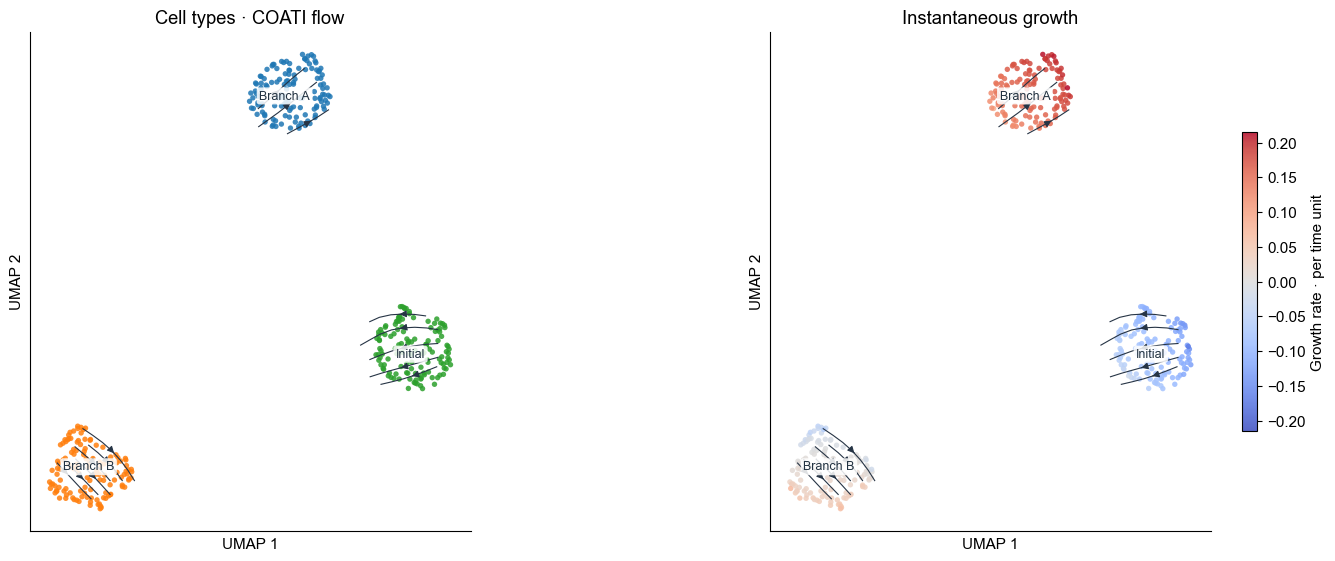

In [4]:
axes = result.plot_dynamics(cells, point_size=15, alpha=.85)
axes[0].figure.savefig(result.output_dir / "dynamics_umap.png", dpi=180, bbox_inches="tight")
axes[0].figure.savefig(result.output_dir / "dynamics_umap.pdf", bbox_inches="tight")
plt.show()

## Evaluate or plot growth separately

Growth is evaluated on the original model features, not on the two UMAP coordinates. `compute_growth` returns the actual derivative of log weight in the saved ODE, including the engine's `alpha_growth` multiplier. It is not cumulative `log_weights`, a cell count, or an experimental proliferation measurement.

Growth rates: (384,) range: -0.16602307558059692 0.2156638205051422


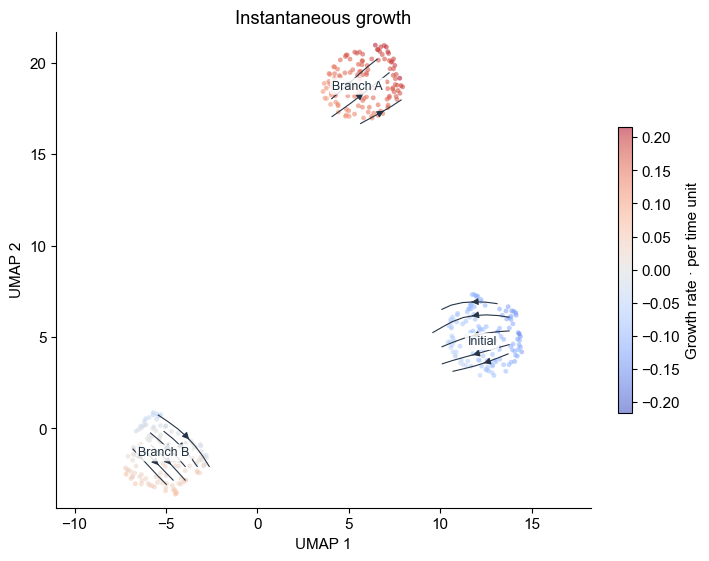

In [5]:
if not balanced:
    growth = result.compute_growth(cells.obsm["X_coati"], time=cells.obs["time"].to_numpy())
    print("Growth rates:", growth.shape, "range:", float(growth.min()), float(growth.max()))
    result.plot_growth(cells, show_velocity=True)
    plt.show()

## Store results without changing the input

`write_dynamics(copy=True)` stores the primary velocity, projected UMAP velocity and (for an unbalanced model) instantaneous growth. Barcodes, supplied labels and row order stay aligned. The AnnData can then be used by other analysis tools.

In [6]:
stored = result.write_dynamics(cells, copy=True)
assert "coati_growth" not in cells.obs
assert "coati_velocity" not in cells.obsm
stored.write_h5ad(result.output_dir / "dynamics.h5ad")
restored = ct.load_result(result.output_dir)
np.testing.assert_array_equal(result.compute_velocity(), restored.compute_velocity())
if not balanced:
    np.testing.assert_array_equal(result.compute_growth(), restored.compute_growth())
    np.testing.assert_allclose(stored.obs["coati_growth"], growth)
print("Saved fields:", list(stored.obs.columns))
print("Saved embeddings:", list(stored.obsm))
print("Output:", result.output_dir)

Saved fields: ['time', 'celltype', 'barcode', 'coati_growth']
Saved embeddings: ['X_coati', 'X_umap', 'coati_velocity', 'coati_velocity_umap']
Output: /Users/jingfeng/local/project/COATI/outputs/dynamics-cc2a0dc9


## Use an existing biological AnnData

Choose the **same prepared representation** used by the trained model. For example:

```python
cells = ct.prepare_anndata(
    adata, use_rep="X_pca", time_key="day", celltype_key="cell_type",
    barcode_key="cell_id", time_mapping={"E14.5": 0., "E15.5": 1., "E16.5": 2.},
)
result = ct.train_vector_field(cells, balanced=False, iterations=1000)
result.plot_dynamics(cells)
```

Omit `time_mapping` when the selected times are already numeric in the intended training units. If the original AnnData has several time columns, select the one you intend; the helper does not decide their biological meaning. For multimodal training, provide paired secondary features in the same rows and select `multimodal=True` with `secondary_obsm_key="X_atac"`.

The short synthetic run verifies this workflow. It does not establish convergence of population mass or biological accuracy.